# Gaussian Mixture y DBSCAN 
En esta practica estudiaremos dos modelos más de clustering. 

Gaussian Mxture es un modelo basado en probabilidades el cual nos permite trabajar clusteres de forma suave, mientras que DBSCAN es un modelo basado en densidades el cual puede detectar formas complejas y con alta densidad. 

La idea de esta practica es trabajar con datos sinteticos generados por `make_blobs` para estudiar el comportamiento de estos modelos de clustering en una estructura sencilla y controlada. Tambien se pondrá a prueba una implementación de cero que realice de DBSCAN, para compararlo con la función de sklearn.

### Gaussian Mixture
GM se basa en probabilidad, asumiendo una densidad guassiana de la forma
$$P(X|\theta) = \sum_{i = 1}^K \pi_i N(\mu_i, \Sigma_i)$$
donde $\theta$ representa al conjunto de parametros de la convinacion de gaussiana.  $\pi_i$ representa la probabilidad de que un punto pertenezca a la gaussiana $i$.
GM busca encontrar los parametros correctos para la densidad que se asume. Las cuentas se hacen usando probabilidad bayesiana y para encontrar los parametros correctos se hace uso de un algoritmo iterativo pues no hay una formula cerrada. 


### DBSCAN 
Este algoritmo se basa en idea de bolas dentro del espacio. 
Sea $X$ el conjunto de datos, una bola en el punto $p$ se define como:
$$ N_\epsilon (p) := \{p \in X : d(p, q) \leq \epsilon \}$$
La idea de dbscan consiste es divir todos los datos en tres tipos: `central` `frontera` y `ruido`. 

`central`:= $\{p \in X : |N_\epsilon(p)| \geq Min pts\}$
`frontera`: No es central pero pertenece a la bola de un punto central 
`ruido`: Ni central ni frontera  

La forma en la que se crean los clusteres en dbscan es haciendo conectividad de los puntos centrales. Se busca los puntos centrales que pertenezcan a la bola de otro punto central y asi se va haciendo un camino de puntos centrales. Al considerar esos puntos del camino juntos a los frontera, se forma un cluster.

-----

In [61]:
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.cluster import DBSCAN as sklearnDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs

## Generación y exploración de datos 

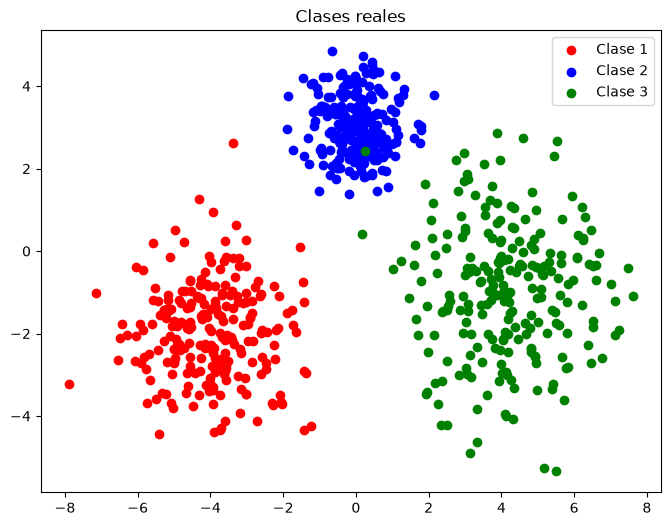

In [62]:
X, y = make_blobs(n_samples=700, n_features=2, centers=[(-4, -2), (0, 3), (4, -1)], cluster_std=[1.2, 0.7, 1.5], random_state=42)
#visualizacion
colores = ['red', 'blue', 'green']
clases = ['Clase 1', 'Clase 2', 'Clase 3']

plt.figure(figsize=(8, 6))
plt.title('Clases reales')

for clase_id in np.unique(y):
    #solo los puntos que pertenecen a esta clase
    mascara = (y == clase_id)
    plt.scatter(X[mascara, 0], X[mascara, 1], color=colores[clase_id], label=clases[clase_id])

plt.legend()
plt.show()

Visualmente si podemos notar que existen tres clusteres con distinta dispersion (dos mas dispersos y uno más compacto). En los bordes si puede haber confusiones sobre a cual cluster pertenecen los puntos, en particular entre el grupo de la derecha y el de arriba.

---

## Prueba con Gaussian Mixture 

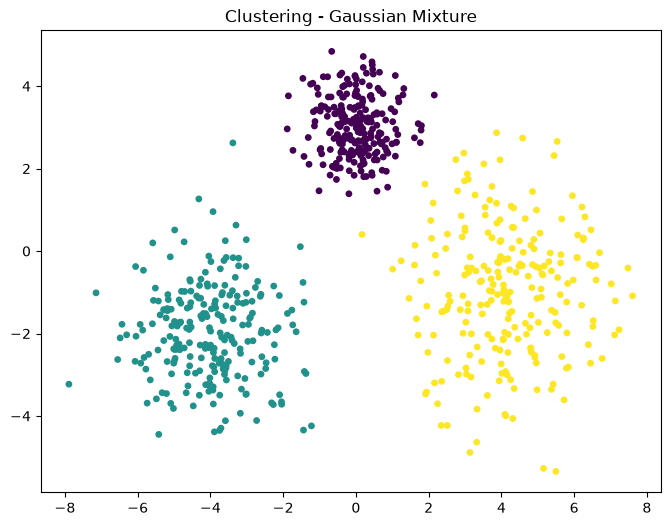

In [63]:
gm = GaussianMixture(n_components=3, covariance_type='full', n_init=10, random_state=42)
etiquetas = gm.fit_predict(X)
# Gráfico de dispersión bidimensional
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=etiquetas, cmap='viridis', s=15)
plt.title("Clustering - Gaussian Mixture")
plt.show()

### Parametros aprendidos por el modelo

In [64]:
medias = gm.means_
covarianzas = gm.covariances_
pesos = gm.weights_

print(f'Las medias obtenidas por el modelo son: ')
print(medias )
print('----'*30)
print(f'Las covarianzas son:')
print(covarianzas)
print('----'*30)
print(f'Los pesos son:')
print(pesos)

Las medias obtenidas por el modelo son: 
[[ 0.00948154  3.02762464]
 [-4.00274017 -1.9700585 ]
 [ 4.16289509 -0.98454578]]
------------------------------------------------------------------------------------------------------------------------
Las covarianzas son:
[[[ 0.45793709 -0.01628073]
  [-0.01628073  0.51873514]]

 [[ 1.36819368 -0.02710325]
  [-0.02710325  1.31169491]]

 [[ 1.90358021 -0.01781981]
  [-0.01781981  2.53742165]]]
------------------------------------------------------------------------------------------------------------------------
Los pesos son:
[0.33400463 0.33425263 0.33174273]


Las medias obtenidas son los centros de cada cluster, mientras que las covarianzas nos dices que tan "expandidos" orizontal y verticalmente estan los datos. Los pesos aprendidos son $0.3$ aproximadamente para cada cluster y tiene sentido pues cada grupo tiene cerca de una tercera parte de los datos totales

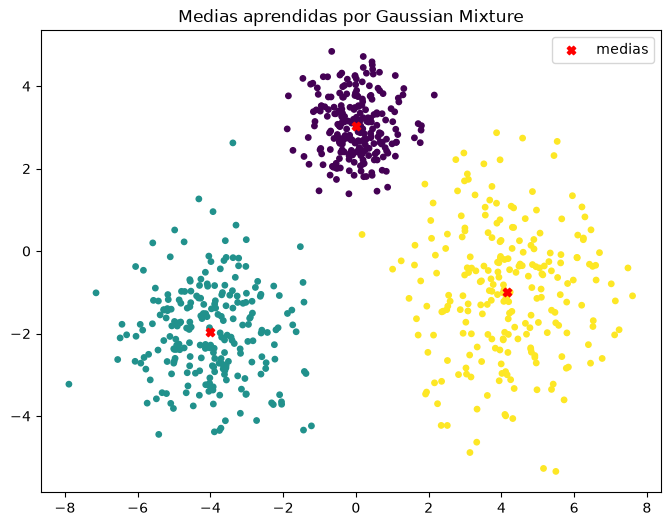

In [65]:
#grafico con las medias aprendidas
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=etiquetas, cmap='viridis', s=15)
plt.scatter(medias[:, 0], medias[:, 1], color = 'red', marker='X', label = 'medias')
plt.title("Medias aprendidas por Gaussian Mixture")
plt.legend()
plt.show()

### Probabilidades de pertenencia

In [66]:
#obtener las probas de cada punto 
probas = gm.predict_proba(X)

#dos puntos con proba de pertenencia bastante clara 
p1 = probas[15]
p2 = probas[50]
print(f'La proba de pertenecia al cluster {np.argmax(p1) + 1} para el punto 1 es de {max(p1)}')
print(f'La proba de pertenecia al cluster {np.argmax(p2) + 1} para el punto 2 es de {max(p2)}')

La proba de pertenecia al cluster 2 para el punto 1 es de 0.9999999590007054
La proba de pertenecia al cluster 1 para el punto 2 es de 0.9997124967837169


In [67]:
mascara = probas.max(axis=1) < 0.8
indices = np.where(mascara)[0]
q1, q2 = indices[0], indices[1]
print(f'Las probas del punto {q1} son ')
print(probas[q1])
print('---'*30)
print(f'Las probas del punto {q2} son ')
print(probas[q2])

Las probas del punto 201 son 
[7.89476285e-01 1.56977899e-10 2.10523715e-01]
------------------------------------------------------------------------------------------
Las probas del punto 368 son 
[0.34991048 0.01718181 0.63290771]


Solo tenemos 2 puntos que cumplen con tener proba maxima de pertenencia menor a 0.8, entonces podemos decir que el algoritmo tiene bien definidas las pertenencias a los clusteres y no tiene tanta confusion.

/var/folders/6f/cl93v53x4kvg964cp1lrrmp40000gn/T/ipykernel_22196/3969499344.py:5: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X[:, 0], X[:, 1], c='black', cmap='viridis', s=15)


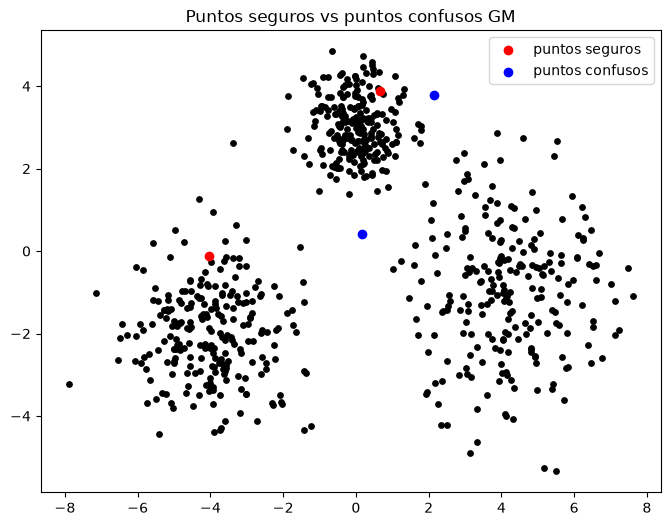

In [68]:
#grafico con los puntos confusos y seguros 
puntos_seguros = np.array([X[15], X[50]])
puntos_confusos = np.array([X[201], X[368]])
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c='black', cmap='viridis', s=15)
plt.scatter(puntos_seguros[:, 0], puntos_seguros[:, 1], color = 'red', label = 'puntos seguros')
plt.scatter(puntos_confusos[:, 0], puntos_confusos[:, 1], color = 'blue', label = 'puntos confusos')
plt.title("Puntos seguros vs puntos confusos GM")
plt.legend()
plt.show()

Podemos notar que como se dijo en un inicio, los puntos entre la nube central y la de la derecha podrian llegar a causar confusion por la cercania entre ellos. 

## Prueba con DBSCAN 
Probaremos este algoritmo usando la implementación de sklearn al igual que la implementacion propia para comparar resultados (usando los mismos parametros)


In [69]:
## implementación propia 
class DBSCAN:
    def __init__(self, eps: float, minpts: int):
        self.eps = eps 
        self.minpts = minpts
        self.labels_ = None

    def fit(self, X):
        #calcular la distancia entre cada punto
        n = len(X)
        d = np.zeros((n, n))
        for i, p in enumerate(X):
            for j, q in enumerate(X):
                d[i][j] = np.linalg.norm(p - q)

        #calcular los puntos que estan en el epsilon-vecindario        
        puntos_eps = np.zeros(n)
        for h, v in enumerate(d):
            puntos = 0 
            for dis in v:
                if dis <= self.eps:
                    puntos += 1 
            puntos_eps[h] = puntos 

        #definir si un punto es central, frontera o ruido 
        #-1 ruido, 0 frontera, 1 central 
        puntos = np.zeros(n) 
        for i, v in enumerate(puntos_eps):
            if v >= self.minpts: 
                puntos[i] = 1  #nucleo

            else:
                es_frontera = False 
                for x in range(n):
                    if (d[i][x] <= self.eps) and (i != x):
                        if puntos_eps[x] >= self.minpts:
                            es_frontera = True
                            break
                
                if es_frontera:
                    puntos[i] = 0
                else:
                    puntos[i] = -1

        #crear clusteres 
        copia_puntos = np.copy(puntos)
        # indice del punto con su tipo de punto 
        ind_punto = [[u, v] for u, v in zip(range(n), copia_puntos)]

        Clusteres = [] #indices 

        centros = [v for v in ind_punto if v[1] == 1]
        fronteras = [v for v in ind_punto if v[1] == 0]
        
        while len(centros) != 0:
            a = np.random.choice(len(centros))
            centro_act = centros[a]

            #calcular cuantos centros estan cerca del centro actual 
            def buscar_centros(c):
                centro_cerca = []
                for centro in centros:
                    if d[centro[0]][c[0]] <= self.eps:
                        centro_cerca.append(centro) 
                return centro_cerca
            
            centro_cerca = buscar_centros(centro_act)
            
            #calculamos los centros conectados a los centros cerca del centro actual
            i = 0
            while i < len(centro_cerca):
                c_actual = centro_cerca[i]
                nuevos_centros = buscar_centros(c_actual)
    
                for elem in nuevos_centros:
                    if elem not in centro_cerca:
                        centro_cerca.append(elem)
                i += 1

            #metemos todos los puntos densos en el mismo cluster
            cluster = []
            while len(centro_cerca) > 0:
                centro = centro_cerca.pop(0)  #borramos el centro actual de todos los conectados y lo agregamos al cluster
                cluster.append(centro[0])
                for x in fronteras[:]: #agregamos los puntos frontera al cluster
                    if d[x[0]][centro[0]] <= self.eps:
                        cluster.append(x[0])
                        fronteras.remove(x)

                if centro in centros:
                    centros.remove(centro)  #asegurarnos de que el centro ya no este 
            Clusteres.append(cluster)
        
        # iniciamos todo con ruido
        labels = np.full(n, -1)

        for j, cluster in enumerate(Clusteres):
            labels[cluster] = j

        self.labels_ = labels
        return self 

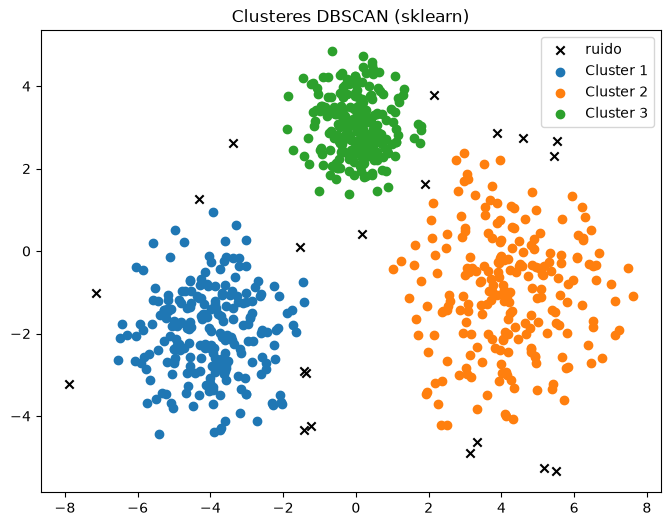

In [85]:
db1 = sklearnDBSCAN(eps = 0.8, min_samples=5)
db1.fit(X)
labels1 = db1.labels_

plt.figure(figsize=(8, 6))
plt.title('Clusteres DBSCAN (sklearn)')

for label in (np.unique(labels1)):
    mascara = labels1 == label
    if label == -1:
        plt.scatter(X[mascara, 0], X[mascara, 1], marker='x',color = 'black', label = f'ruido')
    else:
        plt.scatter(X[mascara, 0], X[mascara, 1], label = f'Cluster {label+1}')


plt.legend()
plt.show()

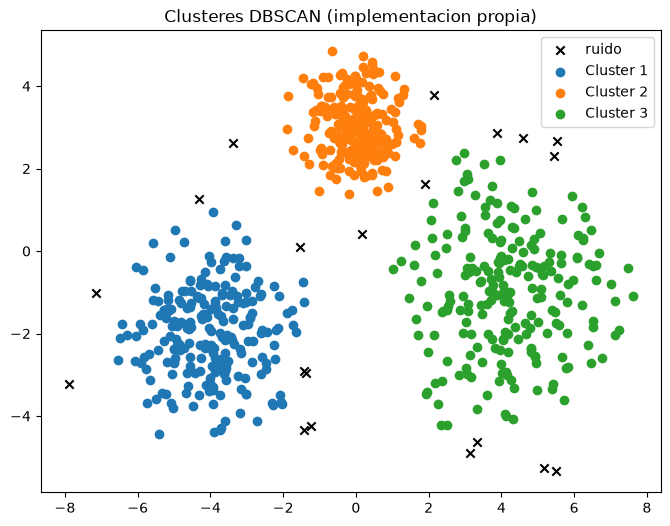

In [86]:
db2 = DBSCAN(eps = 0.8, minpts=5)
db2.fit(X)
labels2 = db2.labels_

plt.figure(figsize=(8, 6))
plt.title('Clusteres DBSCAN (implementacion propia)')

for label in (np.unique(labels2)):
    mascara = labels2 == label
    if label == -1:
        plt.scatter(X[mascara, 0], X[mascara, 1], marker='x',color = 'black', label = f'ruido')
    else:
        plt.scatter(X[mascara, 0], X[mascara, 1], label = f'Cluster {label+1}')


plt.legend()
plt.show()


En ambos casos DBSCAN encontró 3 clusteres con los mismos puntos de ruido, encontradas en las orillas de cada cluster. Podemos notar que el ruido está encontrado de buena forma pues no se encuentra en las zonas más densas de los grupos. DBSCAN nos permite eliminar estos puntos que pareciera que no estan en ningun cluster en especifico. 

### Ahora jugaremos con los parametros de DBSCAN dejando fijo alguno de los dos y dejando correr el otro.

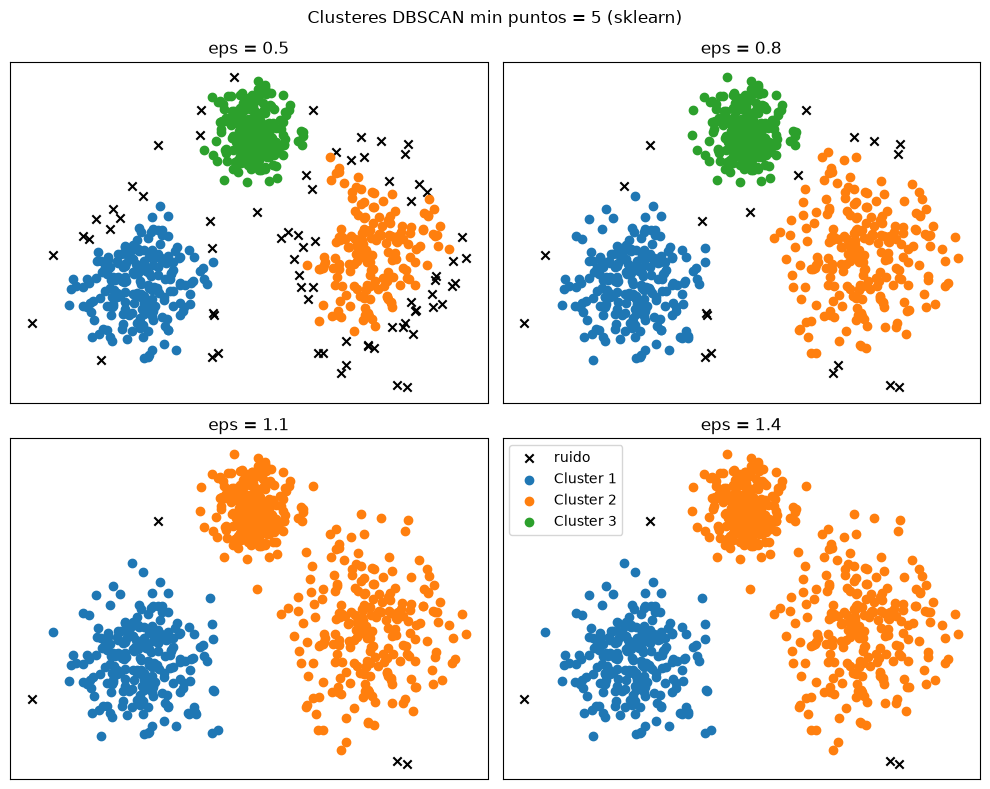

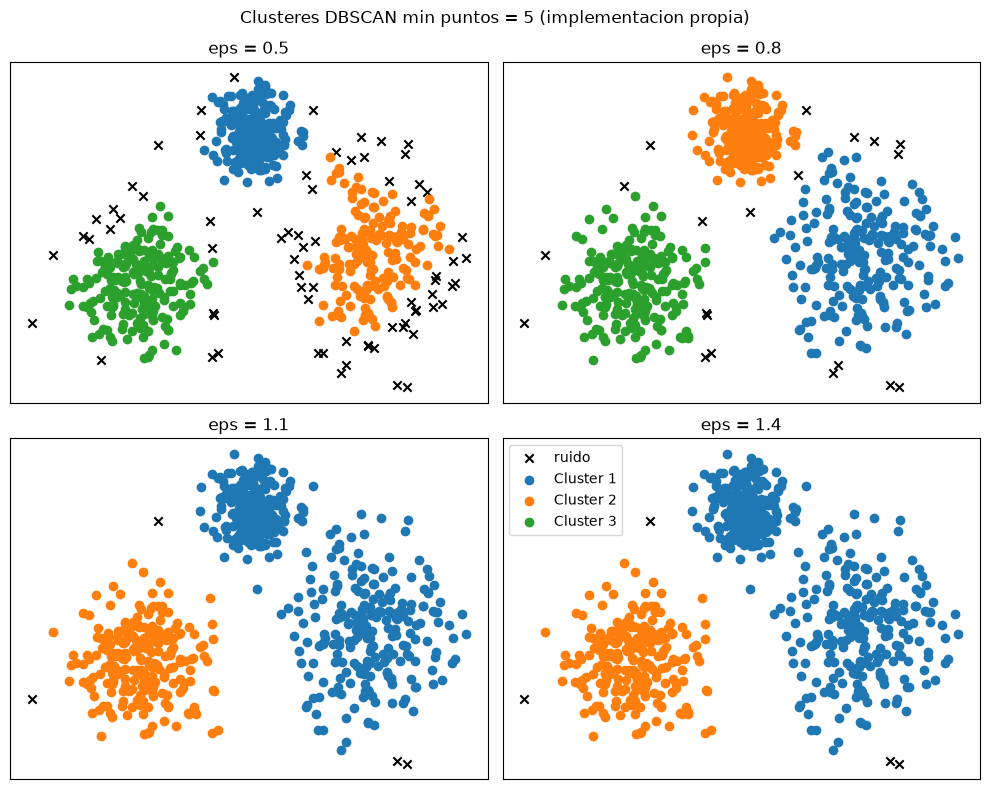

In [107]:
min_examples = 5
eps = [0.5, 0.8, 1.1, 1.4]

for modelo in [sklearnDBSCAN, DBSCAN]:
    fig, ax = plt.subplots(2, 2, figsize=(10, 8))
    ax = ax.flatten()
    if modelo == sklearnDBSCAN:
        fig.suptitle('Clusteres DBSCAN min puntos = 5 (sklearn)')

    else:
        fig.suptitle('Clusteres DBSCAN min puntos = 5 (implementacion propia)')
    for i,e in enumerate(eps):

        if modelo == sklearnDBSCAN:
            db = modelo(eps = e, min_samples=min_examples)
        else:
            db = modelo(eps = e, minpts=min_examples)

        db.fit(X)
        labels = db.labels_

        ax[i].set_title(f'eps = {e}')
        for label in (np.unique(labels1)):
            mascara = labels == label
            if label == -1:
                ax[i].scatter(X[mascara, 0], X[mascara, 1], marker='x',color = 'black', label = f'ruido')
            else:
                ax[i].scatter(X[mascara, 0], X[mascara, 1], label = f'Cluster {label+1}')
        ax[i].set_yticks([])
        ax[i].set_xticks([])
    ax[-1].legend()
    plt.tight_layout()
    plt.show()

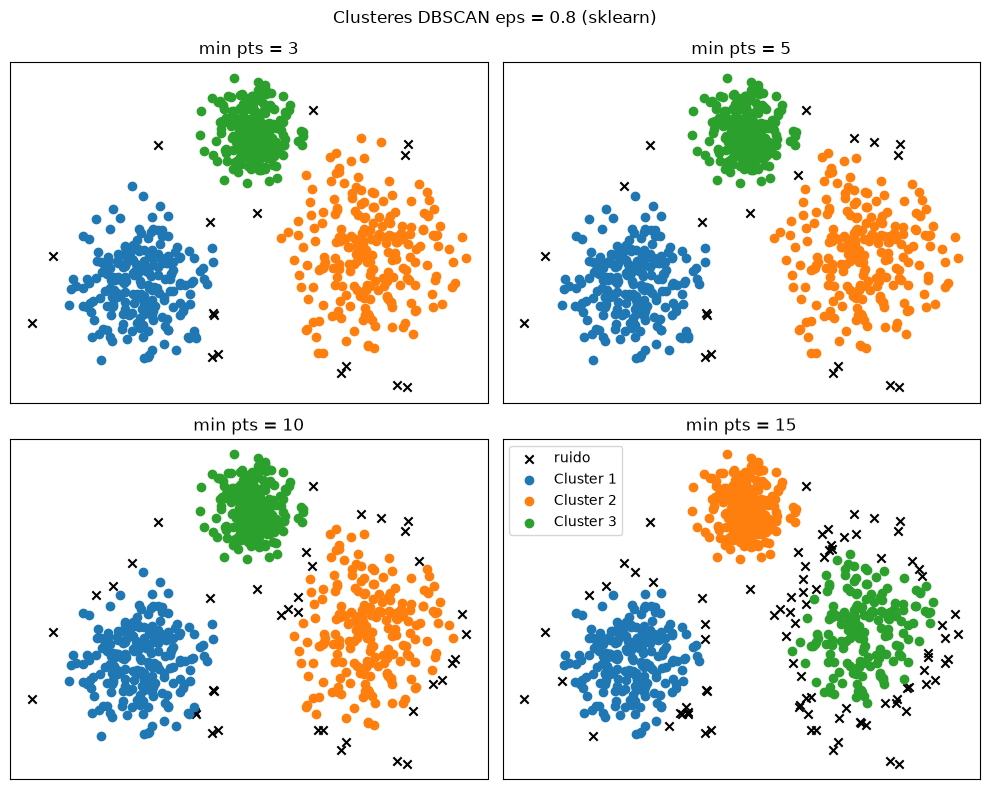

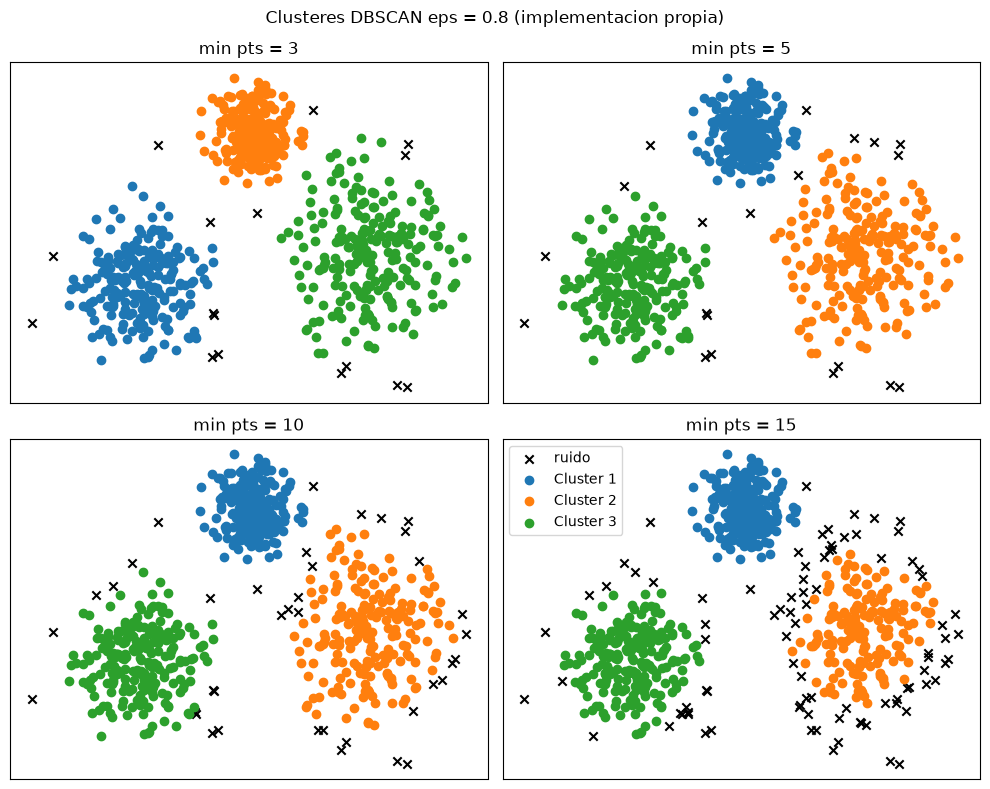

In [108]:
eps= 0.8
min_examples = [3, 5, 10, 15]


for modelo in [sklearnDBSCAN, DBSCAN]:
    fig, ax = plt.subplots(2, 2, figsize=(10, 8))
    ax = ax.flatten()
    if modelo == sklearnDBSCAN:
        fig.suptitle('Clusteres DBSCAN eps = 0.8 (sklearn)')

    else:
        fig.suptitle('Clusteres DBSCAN eps = 0.8 (implementacion propia)')
    for i, puntos in enumerate(min_examples):

        if modelo == sklearnDBSCAN:
            db = modelo(eps = eps, min_samples=puntos)
        else:
            db = modelo(eps = eps, minpts=puntos)

        db.fit(X)
        labels = db.labels_

        ax[i].set_title(f'min pts = {puntos}')
        for label in (np.unique(labels1)):
            mascara = labels == label
            if label == -1:
                ax[i].scatter(X[mascara, 0], X[mascara, 1], marker='x',color = 'black', label = f'ruido')
            else:
                ax[i].scatter(X[mascara, 0], X[mascara, 1], label = f'Cluster {label+1}')
        ax[i].set_yticks([])
        ax[i].set_xticks([])
    ax[-1].legend()
    plt.tight_layout()
    plt.show()

Con esta ultima comparacion podemos notar que las dos implentaciones producen los mismo resultados y es esperable pues dbscan es casi determinista una vez que se fijan los parametros. La idea aqui era ver si la implementacion propia estaba bien, comparando con el algoritmo de sklearn.

Ahora pasando al analisis:

Cuando los valores de epsilon aumentan tenemos que los valores de ruido van disminuyendo debido a que nuestras bolas se vuelven más grandes, aceptando más puntos de ruido. 

Algo contrario pasa cuando los puntos minimos aumentan, el ruido tambien lo hace. Los puntos centrales requieren más puntos entonces empiezan a disminuir y por ende el camino formado por ellos tambien lo hace.

## Comparación de los metodos 
Ahora para terminar vamos a comparar las metricas homogeneidad, completitd y vscore en los algoritmos vistos:

`K-means`, `Mean Shift`, `Agglomerative`, `DBSCAN` y `Gaussian mixture`

In [110]:
from sklearn.metrics import homogeneity_completeness_v_measure
from sklearn.cluster import KMeans, MeanShift, AgglomerativeClustering, estimate_bandwidth
import pandas as pd

In [112]:
resultados = {
    'Métrica': ['Homogeneidad', 'Completitud', 'V-Measure'],
    'K-means': [],
    'Mean shift': [],
    'Agglomerative': [],
    'DBSCAN': [],
    'Gaussian mixture': []
}

# Gaussian mixture ya lo corrimos al inicio del notebook al igual que dbscan hace unas celdas
resultados['Gaussian mixture'] = list(homogeneity_completeness_v_measure(y, etiquetas))

resultados['DBSCAN'] = list(homogeneity_completeness_v_measure(y, labels1))

#ahora corremos los demas modelos y obtenemos las metricas 
#kmeans
kmeans = KMeans(n_clusters=3).fit(X)
labels_kmeans = kmeans.labels_
resultados['K-means'] = list(homogeneity_completeness_v_measure(y, labels_kmeans))

#mean shift
band = estimate_bandwidth(X)
ms = MeanShift(bandwidth=band).fit(X)
labels_ms = ms.labels_
resultados['Mean shift'] = list(homogeneity_completeness_v_measure(y, labels_ms))

#agglomerative 
agg = AgglomerativeClustering(n_clusters=3).fit(X)
labels_agg = agg.labels_
resultados['Agglomerative'] = list(homogeneity_completeness_v_measure(y, labels_agg))


dt = pd.DataFrame(resultados)
display(dt)




,Métrica,K-means,Mean shift,Agglomerative,DBSCAN,Gaussian mixture
0,Homogeneidad,0.950427,0.950427,0.983212,0.96936,0.991609
1,Completitud,0.950724,0.950724,0.983234,0.88986,0.991614
2,V-Measure,0.950576,0.950576,0.983223,0.92791,0.991611


### Podemos notar que los algoritmos producen metricas similares y quiza se deba a que los datos son demasiado bonitos como para retarlos de forma más compleja. Aunque DBSCAN es el algoritmo que tiene una completitud abajo de 0.9, sigue siendo un valor bastante bueno. 

### Las metricas nos indican que todos los algoritmo obtienen buenos clusteres con los datos de prueba que usamos.